In [149]:
import sklearn
import seaborn
import scipy


In [150]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Supervised Learning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Unsupervised Learning
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Cross Validation & Hyperparameter Tuning
from sklearn.model_selection import cross_val_score, GridSearchCV

# Hierarchical Clustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [151]:
df = pd.read_csv("cleaned_ecommerce_data.csv")

In [152]:
df.head()

,Unnamed: 0,Order_ID,Customer_ID,Customer_Name,Age,Region,City,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price,Discount,Revenue,Payment_Method,Delivery_Status,Customer_Rating,Marketing_Channel
0,0,ORD1000,Unknown,Priya Patel,25.0,North,Delhi,2025-03-13,Electronics,Laptop,5,2793,15.0,0,UPI,Delivered,5.0,Unknown
1,1,ORD1001,C151,Riya Shah,31.0,East,Lucknow,04/23/25,Electronics,Headphones,4,2069,10.0,2500,UPI,Delivered,3.0,Instagram
2,2,ORD1002,C207,Rahul Sharma,25.0,West,Mumbai,"Nov 06,2025",Electronics,Smartphone,2,4845,10.0,5000,UPI,Cancelled,3.0,Unknown
3,5,ORD1005,C055,Vikram Das,25.0,North,Jaipur,"Apr 13,2026",Beauty,Perfume,5,2671,15.0,999,UPI,Cancelled,5.0,Google Ads
4,6,ORD1006,C024,Rahul Sharma,31.0,North,Bhopal,09/18/25,Home,Mixer,3,2486,10.0,12000,UPI,Returned,4.0,Unknown


In [153]:
df.shape

(835, 18)

In [154]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         835 non-null    int64  
 1   Order_ID           835 non-null    str    
 2   Customer_ID        835 non-null    str    
 3   Customer_Name      835 non-null    str    
 4   Age                835 non-null    float64
 5   Region             835 non-null    str    
 6   City               835 non-null    str    
 7   Order_Date         835 non-null    str    
 8   Product_Category   835 non-null    str    
 9   Product_Name       835 non-null    str    
 10  Quantity           835 non-null    int64  
 11  Unit_Price         835 non-null    int64  
 12  Discount           835 non-null    float64
 13  Revenue            835 non-null    int64  
 14  Payment_Method     835 non-null    str    
 15  Delivery_Status    835 non-null    str    
 16  Customer_Rating    835 non-null    fl

In [155]:
df.describe()

,Unnamed: 0,Age,Quantity,Unit_Price,Discount,Revenue,Customer_Rating
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,502.760479,30.778443,3.851497,4091.834731,8.550898,8059.704192,3.057485
std,289.405850,11.443952,2.490651,2161.369935,6.256564,10193.839638,1.274751
min,0.000000,21.000000,1.000000,310.000000,0.000000,0.000000,1.000000
25%,249.500000,25.000000,3.000000,2248.500000,5.000000,999.000000,2.000000
50%,510.000000,25.000000,3.000000,4053.000000,10.000000,2500.000000,3.000000
75%,755.000000,31.000000,4.000000,5972.000000,10.000000,12000.000000,4.000000
max,996.000000,60.000000,10.000000,7977.000000,20.000000,30000.000000,5.000000


In [156]:
df.columns

Index(['Unnamed: 0', 'Order_ID', 'Customer_ID', 'Customer_Name', 'Age',
       'Region', 'City', 'Order_Date', 'Product_Category', 'Product_Name',
       'Quantity', 'Unit_Price', 'Discount', 'Revenue', 'Payment_Method',
       'Delivery_Status', 'Customer_Rating', 'Marketing_Channel'],
      dtype='str')

In [157]:
df = df.drop(columns=["Unnamed: 0"])

In [158]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Name', 'Age', 'Region', 'City',
       'Order_Date', 'Product_Category', 'Product_Name', 'Quantity',
       'Unit_Price', 'Discount', 'Revenue', 'Payment_Method',
       'Delivery_Status', 'Customer_Rating', 'Marketing_Channel'],
      dtype='str')

In [159]:
df.nunique()


Order_ID             834
Customer_ID          238
Customer_Name         16
Age                    5
Region                 4
City                   7
Order_Date           687
Product_Category       6
Product_Name          14
Quantity               6
Unit_Price           790
Discount               5
Revenue                6
Payment_Method         4
Delivery_Status        3
Customer_Rating        5
Marketing_Channel      5
dtype: int64

In [160]:
# Numerical Columns
num_cols = df.select_dtypes(include=['int64','float64']).columns

print(num_cols)

Index(['Age', 'Quantity', 'Unit_Price', 'Discount', 'Revenue',
       'Customer_Rating'],
      dtype='str')


In [161]:
# Categorical Columns
cat_cols = df.select_dtypes(include=['object']).columns

print(cat_cols)

Index(['Order_ID', 'Customer_ID', 'Customer_Name', 'Region', 'City',
       'Order_Date', 'Product_Category', 'Product_Name', 'Payment_Method',
       'Delivery_Status', 'Marketing_Channel'],
      dtype='str')


In [162]:
df = df.drop(columns=["Order_ID", "Customer_ID"])

In [163]:
df["Revenue"].unique()

array([    0,  2500,  5000,   999, 12000, 30000])

In [164]:
df["Delivery_Status"].unique()

<StringArray>
['Delivered', 'Cancelled', 'Returned']
Length: 3, dtype: str

In [165]:
df["Revenue"].value_counts()

Revenue
999      147
2500     146
5000     142
0        136
12000    134
30000    130
Name: count, dtype: int64

In [166]:
categorical_columns = [
    "Region",
    "City",
    "Product_Category",
    "Product_Name",
    "Payment_Method",
    "Marketing_Channel"
]

In [167]:
df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=False
)

In [168]:
df.head(30)

,Customer_Name,Age,Order_Date,Quantity,Unit_Price,Discount,Revenue,Delivery_Status,Customer_Rating,Region_East,...,Product_Name_T-Shirt,Payment_Method_Card,Payment_Method_Cash,Payment_Method_UPI,Payment_Method_Wallet,Marketing_Channel_Email,Marketing_Channel_Facebook,Marketing_Channel_Google Ads,Marketing_Channel_Instagram,Marketing_Channel_Unknown
0,Priya Patel,25.0,2025-03-13,5,2793,15.0,0,Delivered,5.0,False,...,False,False,False,True,False,False,False,False,False,True
1,Riya Shah,31.0,04/23/25,4,2069,10.0,2500,Delivered,3.0,True,...,False,False,False,True,False,False,False,False,True,False
2,Rahul Sharma,25.0,"Nov 06,2025",2,4845,10.0,5000,Cancelled,3.0,False,...,False,False,False,True,False,False,False,False,False,True
3,Vikram Das,25.0,"Apr 13,2026",5,2671,15.0,999,Cancelled,5.0,False,...,False,False,False,True,False,False,False,True,False,False
4,Rahul Sharma,31.0,09/18/25,3,2486,10.0,12000,Returned,4.0,False,...,False,False,False,True,False,False,False,False,False,True
5,Karan Mehta,60.0,"Dec 16,2025",3,5670,5.0,5000,Delivered,5.0,True,...,False,False,False,True,False,False,True,False,False,False
6,Amit Singh,25.0,"Mar 20,2025",5,5203,15.0,5000,Delivered,3.0,False,...,False,False,False,True,False,False,False,True,False,False
7,Priya Patel,31.0,02/13/25,4,7565,5.0,12000,Delivered,5.0,False,...,True,False,False,True,False,False,False,False,False,True
8,Vikram Das,45.0,"Jul 24,2025",3,6325,20.0,2500,Cancelled,5.0,False,...,False,False,False,True,False,False,True,False,False,False
9,Sneha Joshi,25.0,2025-02-18,10,5960,15.0,30000,Delivered,1.0,True,...,False,False,False,True,False,True,False,False,False,False


In [169]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 49 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Customer_Name                 835 non-null    str    
 1   Age                           835 non-null    float64
 2   Order_Date                    835 non-null    str    
 3   Quantity                      835 non-null    int64  
 4   Unit_Price                    835 non-null    int64  
 5   Discount                      835 non-null    float64
 6   Revenue                       835 non-null    int64  
 7   Delivery_Status               835 non-null    str    
 8   Customer_Rating               835 non-null    float64
 9   Region_East                   835 non-null    bool   
 10  Region_North                  835 non-null    bool   
 11  Region_South                  835 non-null    bool   
 12  Region_West                   835 non-null    bool   
 13  City_ Mumbai    

In [170]:
df = df.drop(columns=["Customer_Name"])

In [171]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="mixed",
    errors="coerce"
)

In [172]:
df["Order_Date"].isnull().sum()

np.int64(0)

In [173]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Month"] = df["Order_Date"].dt.month
df["Day"] = df["Order_Date"].dt.day
df["Year"] = df["Order_Date"].dt.year

df.drop("Order_Date", axis=1, inplace=True)

In [174]:
df.head()

,Age,Quantity,Unit_Price,Discount,Revenue,Delivery_Status,Customer_Rating,Region_East,Region_North,Region_South,...,Payment_Method_UPI,Payment_Method_Wallet,Marketing_Channel_Email,Marketing_Channel_Facebook,Marketing_Channel_Google Ads,Marketing_Channel_Instagram,Marketing_Channel_Unknown,Month,Day,Year
0,25.0,5,2793,15.0,0,Delivered,5.0,False,True,False,...,True,False,False,False,False,False,True,3,13,2025
1,31.0,4,2069,10.0,2500,Delivered,3.0,True,False,False,...,True,False,False,False,False,True,False,4,23,2025
2,25.0,2,4845,10.0,5000,Cancelled,3.0,False,False,False,...,True,False,False,False,False,False,True,11,6,1
3,25.0,5,2671,15.0,999,Cancelled,5.0,False,True,False,...,True,False,False,False,True,False,False,4,13,1
4,31.0,3,2486,10.0,12000,Returned,4.0,False,True,False,...,True,False,False,False,False,False,True,9,18,2025


In [175]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 50 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Age                           835 non-null    float64
 1   Quantity                      835 non-null    int64  
 2   Unit_Price                    835 non-null    int64  
 3   Discount                      835 non-null    float64
 4   Revenue                       835 non-null    int64  
 5   Delivery_Status               835 non-null    str    
 6   Customer_Rating               835 non-null    float64
 7   Region_East                   835 non-null    bool   
 8   Region_North                  835 non-null    bool   
 9   Region_South                  835 non-null    bool   
 10  Region_West                   835 non-null    bool   
 11  City_ Mumbai                  835 non-null    bool   
 12  City_Ahmedabad                835 non-null    bool   
 13  City_Bhopal     

In [176]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Delivery_Status"] = le.fit_transform(df["Delivery_Status"])

In [177]:
df["Delivery_Status"].unique()

array([1, 0, 2])

In [178]:
X = df.drop("Delivery_Status", axis=1)
y = df["Delivery_Status"]

In [179]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [180]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [181]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (668, 49)
X_test  : (167, 49)
y_train : (668,)
y_test  : (167,)


### Logistic Regression

In [182]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [183]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(random_state=42)

log_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

In [184]:
y_pred = log_model.predict(X_test)

In [185]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 0.6047904191616766


In [186]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 1 36  1]
 [ 3 99  1]
 [ 0 25  1]]


In [187]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.25      0.03      0.05        38
           1       0.62      0.96      0.75       103
           2       0.33      0.04      0.07        26

    accuracy                           0.60       167
   macro avg       0.40      0.34      0.29       167
weighted avg       0.49      0.60      0.49       167



In [188]:
df["Delivery_Status"].value_counts()


Delivery_Status
1    511
0    173
2    151
Name: count, dtype: int64

In [189]:
log_model = LogisticRegression(
    random_state=42,
    class_weight="balanced"
)

log_model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default

### Logistic Regression achieved approximately 60% accuracy. Due to class imbalance in the target variable (Delivery_Status), the model predicted the majority class more effectively than the minority classes.

In [190]:
y_pred = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.3592814371257485
[[11 12 15]
 [31 40 32]
 [ 3 14  9]]
              precision    recall  f1-score   support

           0       0.24      0.29      0.27        38
           1       0.61      0.39      0.47       103
           2       0.16      0.35      0.22        26

    accuracy                           0.36       167
   macro avg       0.34      0.34      0.32       167
weighted avg       0.45      0.36      0.39       167



In [191]:
log_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", log_accuracy)

Accuracy: 0.3592814371257485


# KNN

In [192]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

In [193]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print(confusion_matrix(y_test, y_pred_knn))

print(classification_report(y_test, y_pred_knn))

Accuracy: 0.5568862275449101
[[ 5 29  4]
 [13 87  3]
 [ 0 25  1]]
              precision    recall  f1-score   support

           0       0.28      0.13      0.18        38
           1       0.62      0.84      0.71       103
           2       0.12      0.04      0.06        26

    accuracy                           0.56       167
   macro avg       0.34      0.34      0.32       167
weighted avg       0.46      0.56      0.49       167



In [194]:
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print(confusion_matrix(y_test, y_pred_knn))

print(classification_report(y_test, y_pred_knn))

Accuracy: 0.5568862275449101
[[ 5 29  4]
 [13 87  3]
 [ 0 25  1]]
              precision    recall  f1-score   support

           0       0.28      0.13      0.18        38
           1       0.62      0.84      0.71       103
           2       0.12      0.04      0.06        26

    accuracy                           0.56       167
   macro avg       0.34      0.34      0.32       167
weighted avg       0.46      0.56      0.49       167



In [195]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
print("Accuracy:", knn_accuracy)

Accuracy: 0.5568862275449101


### Decision Tree

In [196]:
from sklearn.tree import DecisionTreeClassifier

In [197]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [198]:
y_pred_dt = dt.predict(X_test)

In [199]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print(confusion_matrix(y_test, y_pred_dt))

print(classification_report(y_test, y_pred_dt))

Accuracy: 0.437125748502994
[[12 15 11]
 [25 54 24]
 [11  8  7]]
              precision    recall  f1-score   support

           0       0.25      0.32      0.28        38
           1       0.70      0.52      0.60       103
           2       0.17      0.27      0.21        26

    accuracy                           0.44       167
   macro avg       0.37      0.37      0.36       167
weighted avg       0.52      0.44      0.47       167



In [200]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print("Accuracy:", dt_accuracy)

Accuracy: 0.437125748502994


### Random forest classifier

In [201]:
from sklearn.ensemble import RandomForestClassifier

In [202]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [203]:
y_pred_rf = rf.predict(X_test)

In [204]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print(confusion_matrix(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

Accuracy: 0.6167664670658682
[[  0  37   1]
 [  0 103   0]
 [  0  26   0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        38
           1       0.62      1.00      0.77       103
           2       0.00      0.00      0.00        26

    accuracy                           0.62       167
   macro avg       0.21      0.33      0.26       167
weighted avg       0.38      0.62      0.47       167



In [ ]:

rf_accuracy = accuracy_score(y_test, y_pred_rf)
print("Accuracy:", rf_accuracy)

Accuracy: 0.6167664670658682


## SVM Support Vector Machine

In [206]:
from sklearn.svm import SVC

In [207]:
svm = SVC(kernel="rbf", random_state=42)

svm.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [208]:
y_pred_svm = svm.predict(X_test)

In [209]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print(confusion_matrix(y_test, y_pred_svm))

print(classification_report(y_test, y_pred_svm))

Accuracy: 0.6167664670658682
[[  0  38   0]
 [  0 103   0]
 [  0  26   0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        38
           1       0.62      1.00      0.76       103
           2       0.00      0.00      0.00        26

    accuracy                           0.62       167
   macro avg       0.21      0.33      0.25       167
weighted avg       0.38      0.62      0.47       167



In [210]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)
print("Accuracy:", svm_accuracy)

Accuracy: 0.6167664670658682


In [211]:
results = {
    "Logistic Regression": 0.60,
    "KNN": knn_accuracy,
    "Decision Tree": dt_accuracy,
    "Random Forest": rf_accuracy,
    "SVM": svm_accuracy
}

In [212]:
import pandas as pd

results = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        log_accuracy,
        knn_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy
    ]
})

print(results)

             Algorithm  Accuracy
0  Logistic Regression  0.359281
1                  KNN  0.556886
2        Decision Tree  0.437126
3        Random Forest  0.616766
4                  SVM  0.616766


Five supervised machine learning algorithms were implemented and compared on the e-commerce dataset. Among them, Random Forest and SVM achieved the highest accuracy of 61.68%, making them the best-performing models for this dataset. Logistic Regression achieved the lowest accuracy, while KNN and Decision Tree showed moderate performance.

In [213]:
best_model = results.loc[results["Accuracy"].idxmax()]

print("Best Model:")
print(best_model)

Best Model:
Algorithm    Random Forest
Accuracy          0.616766
Name: 3, dtype: object


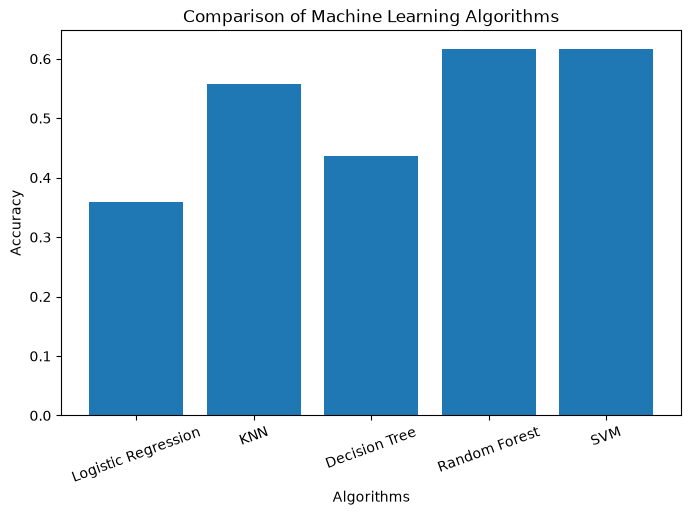

In [214]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(results["Algorithm"], results["Accuracy"])

plt.title("Comparison of Machine Learning Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.show()

# K-Means

In [215]:
from sklearn.cluster import KMeans

In [216]:
X_cluster = X

In [217]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

Train

In [218]:
kmeans.fit(X_cluster)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 49)","[[ 3

In [219]:
clusters = kmeans.labels_

print(clusters)

[0 0 0 0 2 0 0 2 0 1 1 0 0 2 0 0 0 1 0 0 0 0 0 0 2 0 1 0 2 0 0 0 0 1 0 1 2
 0 0 2 0 1 0 0 0 0 0 0 2 1 0 2 0 1 0 0 0 0 0 0 0 0 2 1 2 0 0 0 0 1 1 0 0 0
 0 0 2 0 0 1 0 0 0 0 0 2 1 1 0 0 2 0 0 0 0 1 2 2 0 0 0 0 0 0 0 0 0 1 2 0 0
 0 0 0 2 0 0 2 0 0 0 2 0 0 0 2 1 0 0 0 0 0 2 1 0 0 2 0 2 0 0 0 1 0 0 0 0 0
 0 2 1 2 0 2 1 0 0 0 0 1 1 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 1 0 2 0 0 0 0 0
 1 0 2 2 1 0 0 1 0 0 2 1 1 1 0 0 0 0 1 1 1 0 0 1 2 1 2 0 1 0 0 0 1 0 0 0 2
 0 0 0 0 0 1 1 2 0 0 0 2 0 2 2 2 1 0 1 0 2 1 0 0 0 0 0 0 2 0 0 0 1 1 0 1 0
 0 0 0 2 0 0 1 1 0 0 0 0 2 1 0 2 0 0 0 2 2 0 0 1 0 0 1 0 2 2 0 1 0 0 0 1 0
 0 0 0 0 1 0 2 2 0 1 0 0 0 2 2 0 0 2 0 2 1 1 2 0 1 0 0 0 1 2 0 0 0 0 0 0 0
 1 2 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0 0 2 1 0 0 0 2 0 0 0 0 0 0 0 0 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 1 0 0 2 0 0 0 2 0 0 0 2 0 0 0 0 1 0 1
 0 2 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 2 0 1 0 0 2 0
 0 0 0 1 0 0 1 0 0 0 0 0 2 0 0 0 0 0 0 1 0 0 2 0 0 2 0 0 0 0 0 2 2 2 0 0 0
 0 0 1 0 1 0 0 0 0 0 0 0 

Add into dataset

In [220]:
df["Cluster"] = clusters

In [221]:
print(df["Cluster"].value_counts())

Cluster
0    571
2    134
1    130
Name: count, dtype: int64


In [222]:
print(kmeans.cluster_centers_)

[[3.10192644e+01 3.96497373e+00 4.08770753e+03 8.71278459e+00
  2.13984764e+03 3.04203152e+00 1.10332750e-01 4.60595447e-01
  2.15411559e-01 2.13660245e-01 1.26094571e-01 1.40105079e-01
  2.60945709e-01 1.20840630e-01 1.08581436e-01 1.27845884e-01
  1.15586690e-01 1.24343257e-01 3.16987741e-01 1.94395797e-01
  1.01576182e-01 1.24343257e-01 1.38353765e-01 6.30472855e-02
  5.07880911e-02 5.60420315e-02 5.07880911e-02 8.23117338e-02
  1.13835377e-01 5.95446585e-02 1.06830123e-01 6.12959720e-02
  7.35551664e-02 5.07880911e-02 6.30472855e-02 9.63222417e-02
  7.18038529e-02 2.06654991e-01 2.03152364e-01 3.88791594e-01
  2.01401051e-01 2.01401051e-01 2.17162872e-01 1.83887916e-01
  1.80385289e-01 2.17162872e-01 5.65323993e+00 1.53415061e+01
  1.48289317e+03]
 [2.93307692e+01 3.59230769e+00 4.12800000e+03 8.61538462e+00
  3.00000000e+04 3.17692308e+00 1.53846154e-01 4.30769231e-01
  2.00000000e-01 2.15384615e-01 1.53846154e-01 1.15384615e-01
  2.38461538e-01 1.15384615e-01 7.69230769e-02 1.615

### Visualization

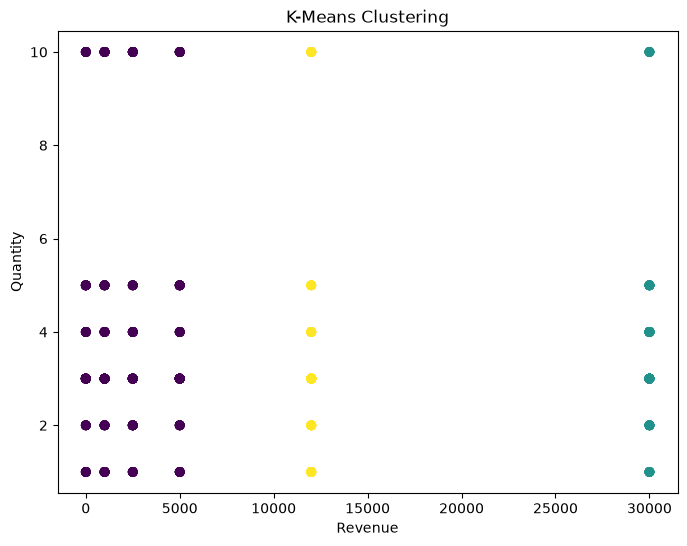

In [223]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    df["Revenue"],
    df["Quantity"],
    c=df["Cluster"]
)

plt.xlabel("Revenue")
plt.ylabel("Quantity")
plt.title("K-Means Clustering")

plt.show()

K-Means is an unsupervised machine learning algorithm that groups similar data points into K clusters based on their distance from the cluster centroids. It does not require a target variable.


# Hierarchical Clustering 

In [224]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

In [225]:
linked = linkage(X_cluster, method="ward")

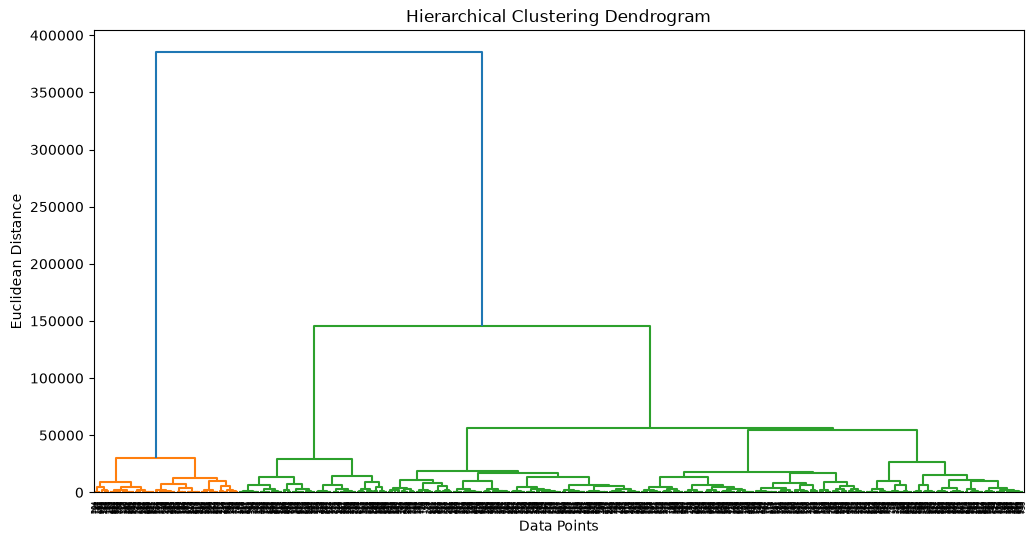

In [226]:
plt.figure(figsize=(12,6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

In [227]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3)

hc_labels = hc.fit_predict(X_cluster)

In [228]:
df["HC_Cluster"] = hc_labels

Check Cluster distribution


In [229]:
print(df["HC_Cluster"].value_counts())

HC_Cluster
0    571
2    134
1    130
Name: count, dtype: int64


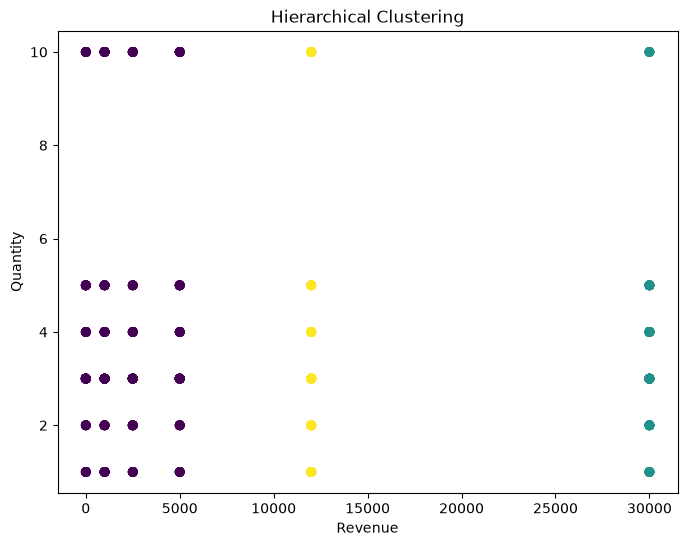

In [230]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["Revenue"],
    df["Quantity"],
    c=df["HC_Cluster"]
)

plt.xlabel("Revenue")
plt.ylabel("Quantity")
plt.title("Hierarchical Clustering")

plt.show()

Hierarchical Clustering is an unsupervised machine learning algorithm that groups similar data points into a hierarchy of clusters. It creates a tree-like structure called a dendrogram.

In [231]:
from sklearn.decomposition import PCA

In [232]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [233]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [234]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df.head()

,PC1,PC2
0,2.111858,0.448937
1,2.479279,0.341041
2,2.208510,0.921697
3,-0.869128,-0.922562
4,-0.941804,-1.385570


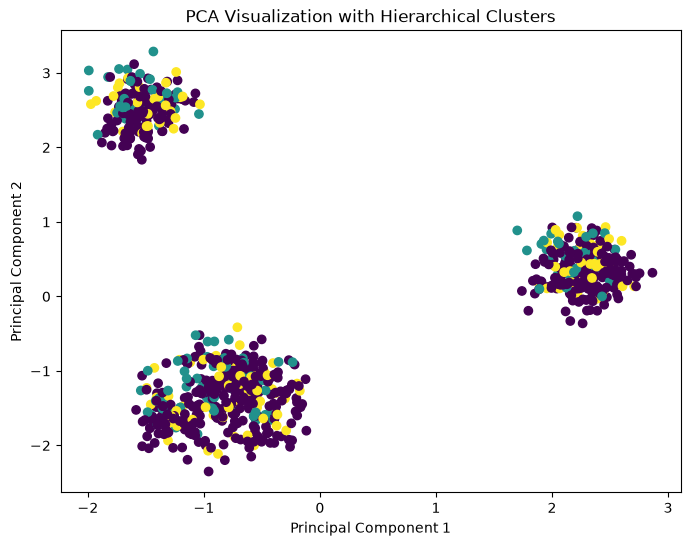

In [235]:
plt.figure(figsize=(8,6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=df["HC_Cluster"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization with Hierarchical Clusters")

plt.show()

In [236]:
explained_variance = pca.explained_variance_ratio_

print("PC1:", explained_variance[0])
print("PC2:", explained_variance[1])

print("Total Variance:", sum(explained_variance))

PC1: 0.05145426510121654
PC2: 0.04778102636016448
Total Variance: 0.09923529146138102


In this project, machine learning techniques were applied to analyze online retail data and extract meaningful insights. Classification models were developed to predict patterns, while clustering algorithms were used to identify similar groups within the dataset. Among classification algorithms, Random Forest and SVM provided the best performance. K-Means and Hierarchical Clustering successfully grouped similar data points, and PCA helped in reducing dimensionality and improving visualization. Overall, the implemented ML pipeline helps in understanding customer behavior, identifying patterns, and supporting data-driven business decisions.